<center><h1>Raza_MohammadHasnain_HW3</h1></center>
<br>
<center><font size="4">Time Series Classification Part 1: Feature Creation/Extraction (AReM Data)</font></center>

**Name:** Mohammad Hasnain Raza  
**GitHub Username:** hasnainrazaa03  
**USC ID:** 1259246355

## 1. Time Series Classification Part 1: Feature Creation/Extraction

### (a) Download Data

Package imports

In [1]:
# all imports and dependencies
import re
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

pd.set_option("display.precision", 4)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")

# seed used for the bootstrap and the cross-validation splits
SEED = 42

Get the AReM Data Set

The data are the AReM files from the UCI repository, unzipped into `../data/AReM/`. There is one folder per activity, and each `datasetK.csv` holds 480 readings (120 s at one reading every 250 ms) of six time series: the mean and variance of the received signal strength (RSS) between each pair of the three body-worn sensors.

As footnote 1 says, a few files need minor cleaning before they can be parsed uniformly:
- `bending2/dataset4.csv` is **space-separated** instead of comma-separated.
- `cycling/dataset9.csv` and `cycling/dataset14.csv` each have one row with a **trailing comma** (an empty 8th field).
- `sitting/dataset8.csv` is **missing the row at t = 13,500 ms**, so it has only 479 readings.

The reader below splits every data line on commas *or* whitespace, so it handles the first two issues. It then reindexes each recording onto the full 480-point time grid and fills any missing time stamp by linear interpolation between its two neighbours. The raw files in `data/` are left untouched.

In [2]:
# relative path to the unzipped AReM folders
DATA_DIR = Path("../data/AReM")

# the six time series in every file, and the seven activity folders
SERIES_NAMES = ["avg_rss12", "var_rss12", "avg_rss13", "var_rss13", "avg_rss23", "var_rss23"]
ACTIVITIES = ["bending1", "bending2", "cycling", "lying", "sitting", "standing", "walking"]

# 480 time stamps, one every 250 ms over 120 seconds
TIME_STAMPS = np.arange(0, 120_000, 250)


def read_recording(file_path):
    # keep the data lines and drop the comment header
    all_lines = [line.strip() for line in file_path.read_text().splitlines()]
    data_lines = [line for line in all_lines if line and not line.startswith("#")]

    # note the files that need cleaning
    fixes = []
    if not any("," in line for line in data_lines):
        fixes.append("space-separated")
    trailing_commas = sum(line.endswith(",") for line in data_lines)
    if trailing_commas:
        fixes.append(f"{trailing_commas} row(s) with a trailing comma")

    # split on commas or spaces, so both formats are read the same way
    value_rows = [[float(value) for value in re.split(r"[,\s]+", line) if value][:7] for line in data_lines]
    raw_df = pd.DataFrame(value_rows, columns=["time"] + SERIES_NAMES)
    raw_df = raw_df.astype({"time": int}).set_index("time")

    # a missing time stamp is filled from the readings on either side
    missing_times = TIME_STAMPS[~np.isin(TIME_STAMPS, raw_df.index)]
    if len(missing_times):
        fixes.append(f"{len(raw_df)} rows; interpolated missing t = {missing_times.tolist()} ms")
    clean_df = raw_df.reindex(TIME_STAMPS).interpolate(method="linear")
    return clean_df, fixes


def dataset_number(file_path):
    # the number in a file name such as dataset12.csv
    return int(re.search(r"\d+", file_path.stem).group())


# read every recording, one activity folder at a time
instances, cleaning_log = [], []
for activity in ACTIVITIES:
    for file_path in sorted((DATA_DIR / activity).glob("dataset*.csv"), key=dataset_number):
        series_df, fixes = read_recording(file_path)
        instances.append({"Activity": activity, "Dataset": dataset_number(file_path), "Series": series_df})
        if fixes:
            cleaning_log.append({"File": f"{activity}/{file_path.name}", "Fixes applied": "; ".join(fixes)})

# every instance should now hold 480 readings of the 6 series
assert all(instance["Series"].shape == (480, 6) and not instance["Series"].isna().any().any() for instance in instances)
print(f"Loaded {len(instances)} instances, each with 6 time series of 480 values.")
display(pd.DataFrame(cleaning_log))
pd.Series({activity: sum(instance["Activity"] == activity for instance in instances) for activity in ACTIVITIES},
          name="Instances").to_frame().T

Loaded 88 instances, each with 6 time series of 480 values.


,File,Fixes applied
0,bending2/dataset4.csv,space-separated
1,cycling/dataset9.csv,1 row(s) with a trailing comma
2,cycling/dataset14.csv,1 row(s) with a trailing comma
3,sitting/dataset8.csv,479 rows; interpolated missing t = [13500] ms


,bending1,bending2,cycling,lying,sitting,standing,walking
Instances,7,6,15,15,15,15,15


**Figure 1** shows the six time series of dataset 4 of each activity (a training instance of every class).

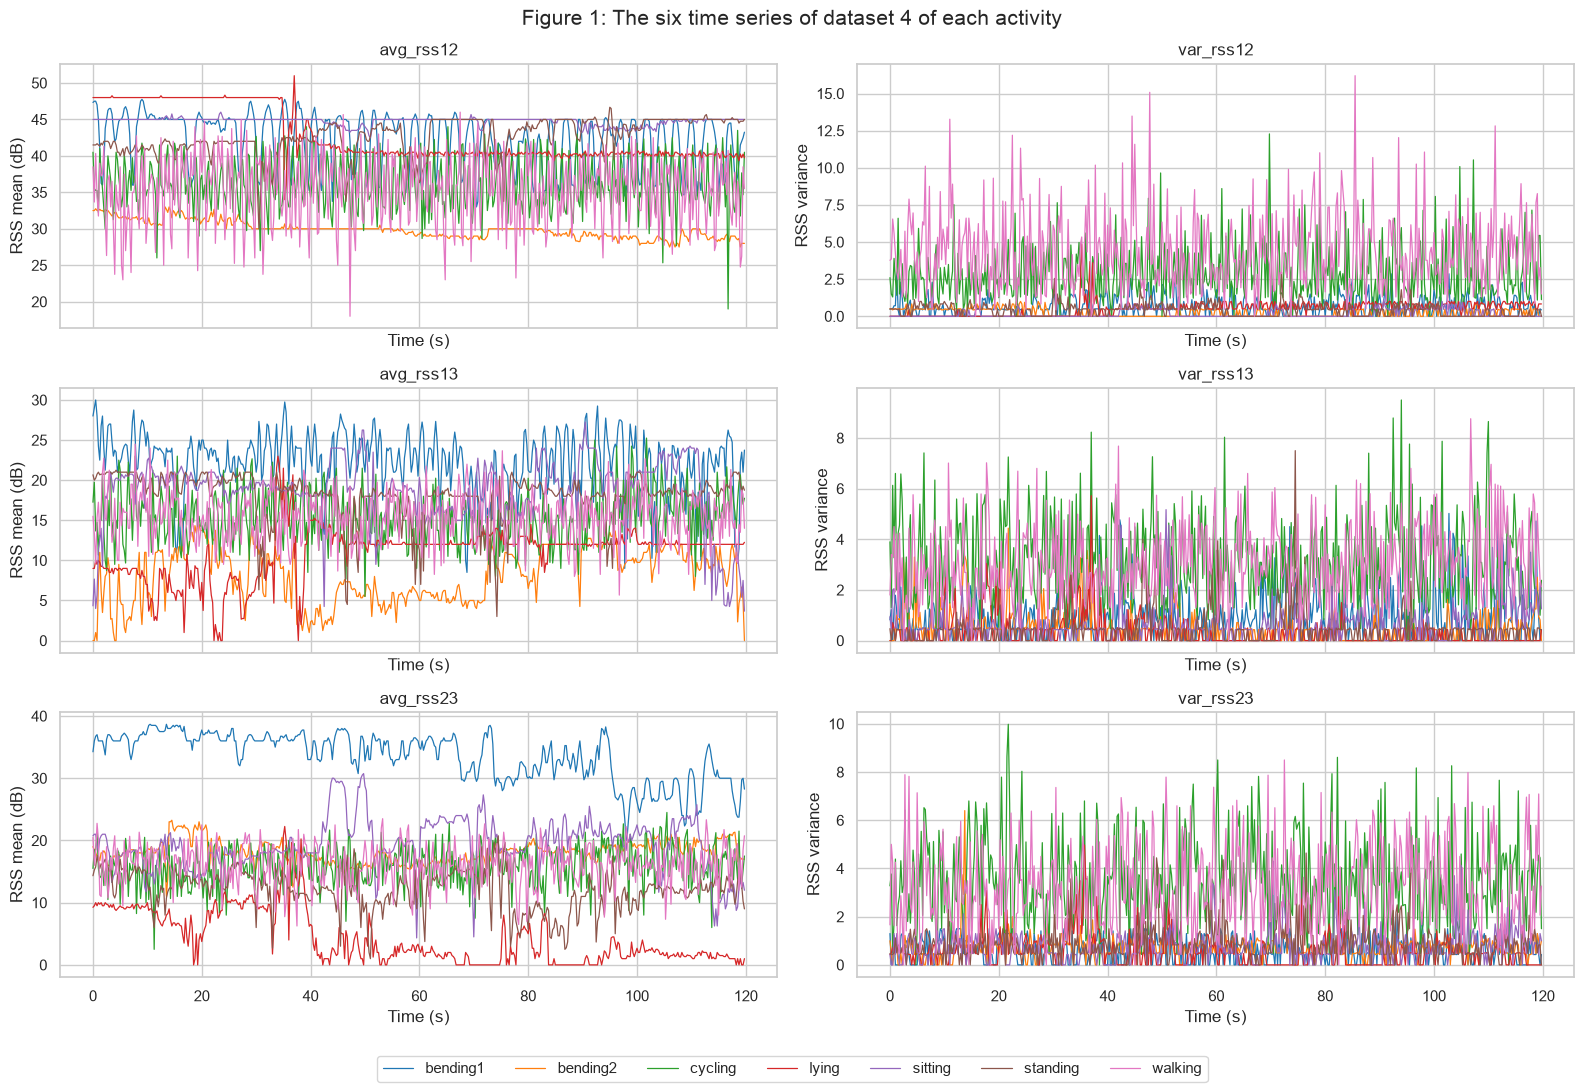

In [3]:
# the six series of one training instance of every activity
fig, axes = plt.subplots(3, 2, figsize=(16, 11), sharex=True)
activity_colors = dict(zip(ACTIVITIES, sns.color_palette("tab10", len(ACTIVITIES))))
for ax, series_name in zip(axes.ravel(), SERIES_NAMES):
    for instance in instances:
        if instance["Dataset"] == 4:
            ax.plot(TIME_STAMPS / 1000, instance["Series"][series_name], lw=0.9,
                    color=activity_colors[instance["Activity"]], label=instance["Activity"])
    ax.set(title=series_name, xlabel="Time (s)",
           ylabel="RSS mean (dB)" if series_name.startswith("avg") else "RSS variance")

# one shared legend below the panels
legend_handles, legend_labels = axes[0, 0].get_legend_handles_labels()
fig.legend(legend_handles, legend_labels, loc="lower center", ncol=len(ACTIVITIES), fontsize=11)
fig.suptitle("Figure 1: The six time series of dataset 4 of each activity", fontsize=15)
plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.show()

### (b) Test and Train Data

Datasets 1 and 2 of `bending1` and `bending2`, and datasets 1, 2 and 3 of the other five activities, form the **test set**. Every other file is **training** data.

In [4]:
def is_test(activity, dataset_num):
    # datasets 1 and 2 of the bending folders, and 1 to 3 of the others, are test data
    return dataset_num <= (2 if activity.startswith("bending") else 3)


# one row per instance, numbered 1 to 88
instance_info = pd.DataFrame(
    {
        "Activity": [instance["Activity"] for instance in instances],
        "Dataset": [instance["Dataset"] for instance in instances],
        "Split": ["test" if is_test(instance["Activity"], instance["Dataset"]) else "train" for instance in instances],
    },
    index=pd.RangeIndex(1, len(instances) + 1, name="Instance"),
)

# train and test counts per activity
split_counts = pd.crosstab(instance_info["Activity"], instance_info["Split"], margins=True, margins_name="Total")
split_counts

Split,test,train,Total
Activity,,,
bending1,2,5,7
bending2,2,4,6
cycling,3,12,15
lying,3,12,15
sitting,3,12,15
standing,3,12,15
walking,3,12,15
Total,19,69,88


**Duplicate recordings.** A pairwise comparison of all 88 recordings shows that the published data contain several (near-)identical files:

In [5]:
# compare every pair of recordings and keep the near-identical ones
duplicate_rows = []
for first_num, second_num in combinations(instance_info.index, 2):
    first_series = instances[first_num - 1]["Series"].to_numpy()
    second_series = instances[second_num - 1]["Series"].to_numpy()
    match_fraction = (first_series == second_series).all(axis=1).mean()
    if match_fraction > 0.95:
        duplicate_rows.append({
            "Recording A": f"{instance_info.at[first_num, 'Activity']}/dataset{instance_info.at[first_num, 'Dataset']} ({instance_info.at[first_num, 'Split']})",
            "Recording B": f"{instance_info.at[second_num, 'Activity']}/dataset{instance_info.at[second_num, 'Dataset']} ({instance_info.at[second_num, 'Split']})",
            "Identical rows": f"{match_fraction:.1%}",
        })
duplicates = pd.DataFrame(duplicate_rows)
duplicates

,Recording A,Recording B,Identical rows
0,cycling/dataset1 (test),cycling/dataset15 (train),100.0%
1,lying/dataset1 (test),lying/dataset10 (train),99.8%
2,lying/dataset1 (test),lying/dataset15 (train),100.0%
3,lying/dataset3 (test),lying/dataset11 (train),100.0%
4,lying/dataset5 (train),lying/dataset12 (train),100.0%
5,lying/dataset7 (train),lying/dataset13 (train),100.0%
6,lying/dataset9 (train),lying/dataset14 (train),100.0%
7,lying/dataset10 (train),lying/dataset15 (train),99.8%


**Answer.** The split gives **69 training instances and 19 test instances**. The pairwise comparison shows that **8 pairs of recordings are (near-)copies of each other** (seven lying pairs and one cycling pair). Several of them cross the split. The test instances `cycling/dataset1`, `lying/dataset1` and `lying/dataset3` also appear in the training set, as `cycling/dataset15`, `lying/dataset15` (plus `lying/dataset10`, which matches in 99.8% of rows) and `lying/dataset11`. The assignment asks for all 88 instances and this fixed split, so I keep every file. When the test error is measured in Homework 4, though, it should be kept in mind that the test predictions for these 3 instances will be optimistic, since the model has already seen their exact features.

### (c) Feature Extraction

#### i. Research

**Answer.** Time-domain features summarize the values of a series directly, without transforming it to the frequency domain. The ones most often used for time series classification, especially with sensor and activity-recognition data, are:

| Group | Features |
|---|---|
| **Location** | mean, median, trimmed mean, mode |
| **Extremes** | minimum, maximum, range (max - min), peak-to-peak amplitude |
| **Spread / dispersion** | variance, standard deviation, mean absolute deviation, coefficient of variation |
| **Order statistics** | first and third quartiles, other percentiles (e.g. 5th / 95th), interquartile range |
| **Shape of the distribution** | skewness, kurtosis |
| **Magnitude / energy** | root mean square (RMS), signal energy $\sum x_t^2$, signal magnitude area, crest factor (peak / RMS) |
| **Temporal dynamics** | mean and std of the first differences, zero-crossing and mean-crossing rates, number of peaks, autocorrelation at a few lags, slope of a fitted linear trend |
| **Complexity** | Hjorth parameters (activity, mobility, complexity), sample / approximate entropy |

The first four groups are the simplest and most widely used, and they are the ones extracted in part ii. They ignore the order of the values, so they describe the *distribution* of each series. The last two groups also capture how the signal changes over time.

#### ii. Extraction

For each of the 6 time series of each instance I extract the seven requested features: minimum, maximum, mean, median, standard deviation (sample, $n-1$), first quartile and third quartile. That gives $6 \times 7 = 42$ features per instance. Quartiles use the default linear interpolation rule. The features are kept on their **original scale** (the question allows this). Parts iii and iv are about the features themselves, and any standardization needed for model fitting is done later inside the model pipeline.

In [6]:
# the seven time-domain features asked for in the question
FEATURE_FUNCS = {
    "min": np.min,
    "max": np.max,
    "mean": np.mean,
    "median": np.median,
    "std": lambda x: np.std(x, ddof=1),
    "1st_quart": lambda x: np.percentile(x, 25),
    "3rd_quart": lambda x: np.percentile(x, 75),
}
FEATURE_NAMES = list(FEATURE_FUNCS)


def extract_features(series_df):
    # seven features for each of the six series, named min1 ... 3rd_quart6
    return {
        f"{feature_name}{series_num}": feature_func(series_df[series_name].to_numpy())
        for series_num, series_name in enumerate(SERIES_NAMES, start=1)
        for feature_name, feature_func in FEATURE_FUNCS.items()
    }


# 88 instances by 42 features, with the activity and the split next to them
features_df = pd.DataFrame([extract_features(instance["Series"]) for instance in instances], index=instance_info.index)
feature_table = instance_info.join(features_df)
print(f"Feature dataset: {features_df.shape[0]} instances x {features_df.shape[1]} features")
feature_table

Feature dataset: 88 instances x 42 features


,Activity,Dataset,Split,min1,max1,mean1,median1,std1,1st_quart1,3rd_quart1,min2,max2,mean2,median2,std2,1st_quart2,3rd_quart2,min3,max3,mean3,median3,std3,1st_quart3,3rd_quart3,min4,max4,mean4,median4,std4,1st_quart4,3rd_quart4,min5,max5,mean5,median5,std5,1st_quart5,3rd_quart5,min6,max6,mean6,median6,std6,1st_quart6,3rd_quart6
Instance,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
1,bending1,1,test,37.25,45.00,40.6248,40.500,1.4770,39.2500,42.0000,0.0,1.30,0.3586,0.430,0.3226,0.0000,0.5000,4.00,29.50,19.0409,19.250,4.4630,16.0000,23.2500,0.0,7.23,0.8325,0.500,0.9657,0.0000,1.1200,27.25,38.25,34.3113,35.000,2.1884,33.0000,36.0000,0.00,1.92,0.5706,0.430,0.5829,0.0000,1.3000
2,bending1,2,test,38.00,45.67,42.8128,42.500,1.4355,42.0000,43.6700,0.0,1.22,0.3724,0.470,0.2892,0.0000,0.5000,2.00,29.50,20.0970,21.000,3.8937,19.0000,22.2500,0.0,5.76,0.8764,0.500,1.0473,0.0000,1.1450,27.67,38.50,33.0246,33.000,1.9953,32.0000,34.5000,0.00,3.11,0.5711,0.430,0.6010,0.0000,1.3000
3,bending1,3,train,35.00,47.40,43.9545,44.330,1.5588,43.0000,45.0000,0.0,1.70,0.4263,0.470,0.3387,0.0000,0.5000,6.50,29.75,22.1224,23.000,3.0309,19.7500,24.0000,0.0,4.44,0.4973,0.430,0.5507,0.0000,0.8300,29.00,38.50,35.5885,36.000,1.9996,35.3625,36.5000,0.00,1.79,0.4933,0.430,0.5135,0.0000,0.9400
4,bending1,4,train,33.00,47.75,42.1798,43.500,3.6707,39.1500,45.0000,0.0,3.00,0.6960,0.500,0.6309,0.0000,1.1200,8.50,30.00,22.1836,23.000,3.8105,20.5000,24.3725,0.0,5.15,0.9899,0.830,0.9537,0.4300,1.3000,20.00,38.67,33.4939,35.000,3.8494,30.4575,36.3300,0.00,2.18,0.6135,0.500,0.5243,0.0000,1.0000
5,bending1,5,train,33.00,45.75,41.6781,41.750,2.2435,41.3300,42.7500,0.0,2.83,0.5360,0.500,0.4055,0.4300,0.7100,3.00,28.25,19.0066,19.125,4.0871,16.5000,22.0625,0.0,6.42,0.8419,0.500,0.9288,0.4300,1.1200,23.67,37.50,29.8571,30.000,2.4110,28.4575,31.2500,0.00,1.79,0.3833,0.430,0.3892,0.0000,0.5000
6,bending1,6,train,37.00,48.00,43.4550,43.250,1.3861,42.5000,45.0000,0.0,1.58,0.3781,0.470,0.3156,0.0000,0.5000,5.75,27.00,15.7933,15.000,3.8476,13.0000,18.2700,0.0,10.03,0.8494,0.500,0.9958,0.4300,1.1200,8.00,33.50,23.0348,23.500,2.4889,22.2500,24.0000,0.00,5.26,0.6796,0.500,0.6225,0.4300,0.8700
7,bending1,7,train,36.25,48.00,43.9691,44.500,1.6184,43.3100,44.6700,0.0,1.50,0.4131,0.470,0.2631,0.4300,0.5000,1.50,26.33,15.8680,16.250,3.7424,14.2500,18.0000,0.0,5.17,0.6664,0.470,0.7890,0.0000,0.9400,11.33,30.75,22.1038,21.670,3.3183,20.5000,23.7500,0.00,2.96,0.5553,0.490,0.4878,0.0000,0.8300
8,bending2,1,test,12.75,51.00,24.5630,24.250,3.7375,23.1875,26.5000,0.0,6.87,0.5908,0.430,0.8374,0.0000,0.7100,0.00,25.33,19.1213,20.250,4.2996,18.0000,22.0000,0.0,6.76,0.7368,0.470,0.9270,0.0000,0.8700,10.67,30.00,23.4930,23.750,3.6938,20.5000,27.0000,0.00,4.97,0.7002,0.500,0.6937,0.4300,0.8700
9,bending2,2,test,0.00,42.75,27.4646,28.000,3.5836,25.5000,30.0000,0.0,7.76,0.4497,0.430,0.7672,0.0000,0.5000,7.50,35.00,20.8425,20.750,3.8263,18.0000,22.5000,0.0,5.76,0.7799,0.500,0.9044,0.0000,0.9400,0.00,33.00,17.6179,18.000,5.0536,15.0000,20.7500,0.00,6.76,1.1221,0.830,1.0123,0.4700,1.3000


#### iii. Standard Deviation

For each of the 42 features, the standard deviation across the 88 instances is estimated with the sample standard deviation. The 90% confidence interval comes from the **bootstrap percentile method**:
1. Draw $B = 10{,}000$ resamples of the 88 instances with replacement.
2. Recompute the standard deviation of each feature in every resample.
3. Take the 5th and 95th percentiles of the $B$ bootstrap standard deviations as the interval.

Whole instances (rows) are resampled, so the 42 features are resampled jointly.

In [7]:
def sample_sd(values, axis):
    # sample standard deviation, recomputed on every resample
    return np.std(values, ddof=1, axis=axis)


# resample whole instances 10,000 times to get a 90% interval for each feature
boot_result = stats.bootstrap(
    (features_df.to_numpy(),),
    sample_sd,
    n_resamples=10_000,
    confidence_level=0.90,
    method="percentile",
    vectorized=True,
    axis=0,
    rng=np.random.default_rng(SEED),
)

# estimate and interval for each of the 42 features
sd_table = pd.DataFrame(
    {
        "Std. dev.": features_df.std(ddof=1),
        "90% CI lower": boot_result.confidence_interval.low,
        "90% CI upper": boot_result.confidence_interval.high,
        "Bootstrap SE": boot_result.standard_error,
    }
)
sd_table.index.name = "Feature"
sd_table

,Std. dev.,90% CI lower,90% CI upper,Bootstrap SE
Feature,,,,
min1,9.5700,8.2360,10.7739,0.7688
max1,4.3944,3.3399,5.2931,0.5931
mean1,5.3357,4.7038,5.8758,0.3568
median1,5.4401,4.7840,6.0063,0.3688
std1,1.7722,1.5694,1.9495,0.1159
1st_quart1,6.1536,5.5738,6.6486,0.3281
3rd_quart1,5.1389,4.3386,5.8340,0.4580
min2,0.0000,0.0000,0.0000,0.0000
max2,5.0627,4.6306,5.4011,0.2354


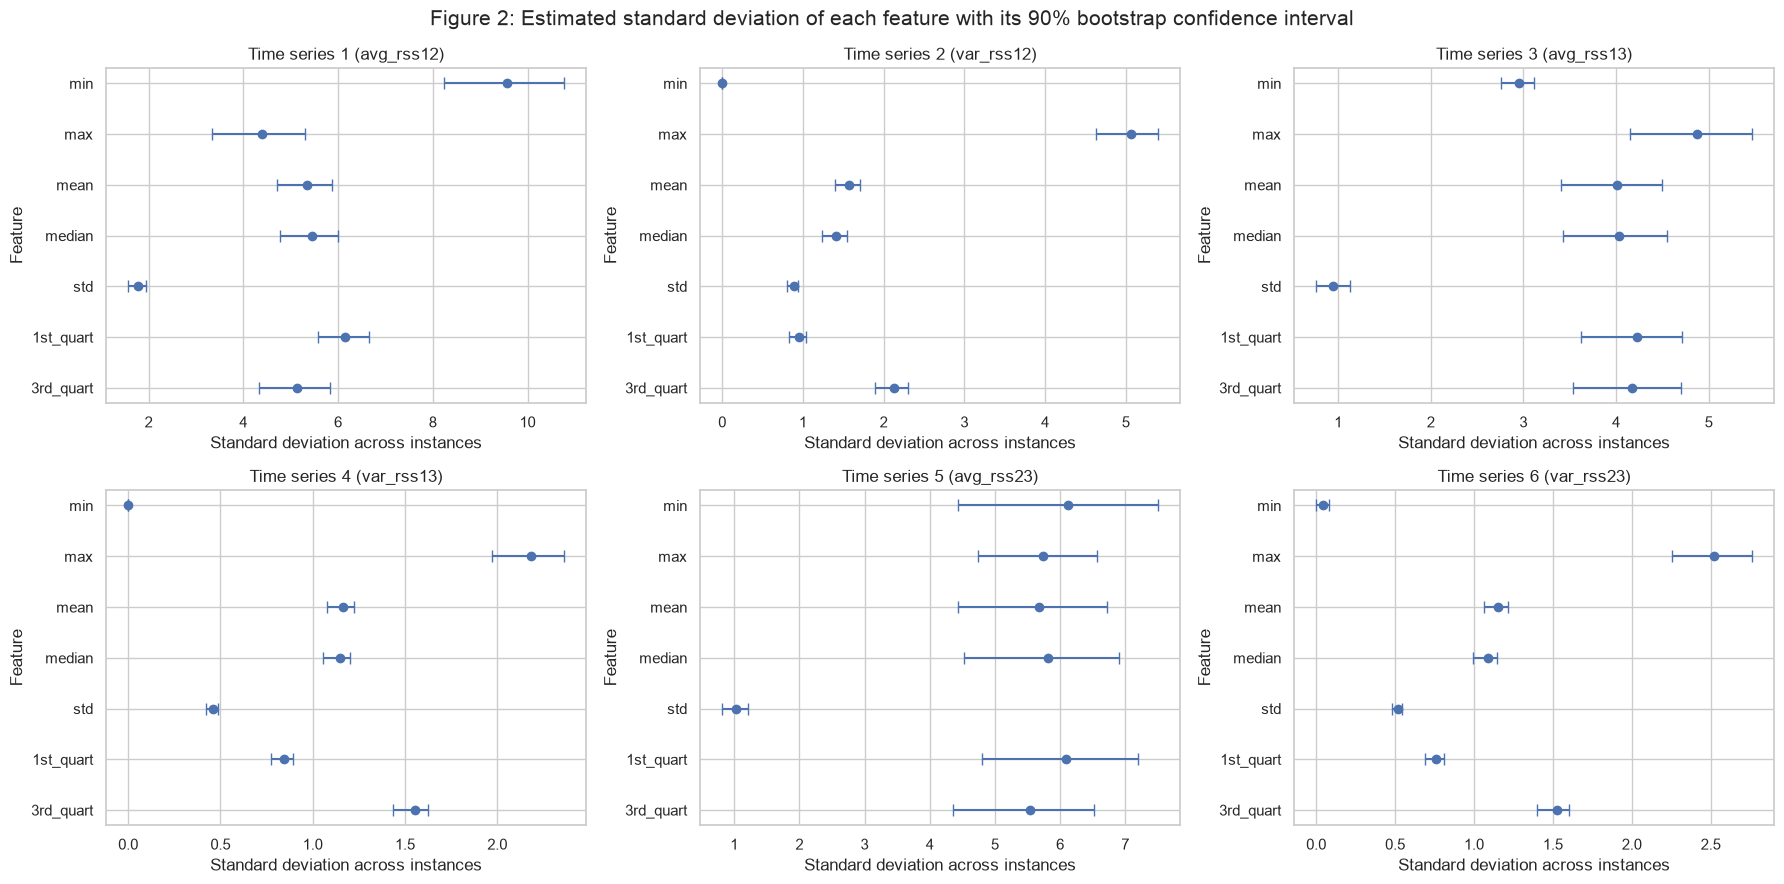

In [8]:
# standard deviation of each feature with its interval, one panel per series
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, (series_num, series_name) in zip(axes.ravel(), enumerate(SERIES_NAMES, start=1)):
    series_sd = sd_table.loc[[f"{feature_name}{series_num}" for feature_name in FEATURE_NAMES]]
    y_positions = np.arange(len(series_sd))
    ax.errorbar(
        series_sd["Std. dev."], y_positions,
        xerr=[series_sd["Std. dev."] - series_sd["90% CI lower"], series_sd["90% CI upper"] - series_sd["Std. dev."]],
        fmt="o", capsize=4,
    )
    ax.set_yticks(y_positions, FEATURE_NAMES)
    ax.invert_yaxis()
    ax.set(title=f"Time series {series_num} ({series_name})", xlabel="Standard deviation across instances", ylabel="Feature")
fig.suptitle("Figure 2: Estimated standard deviation of each feature with its 90% bootstrap confidence interval", fontsize=15)
plt.tight_layout()
plt.show()

**Answer.** The table and Figure 2 give the estimated standard deviation of each feature across the 88 instances, with its 90% bootstrap confidence interval.

- **Two features never vary.** `min2` and `min4` (the minima of `var_rss12` and `var_rss13`) are **0 in every instance**, so their standard deviation and whole confidence interval are exactly 0. `min6` is almost constant too (s = 0.046, CI [0, 0.079]). The variance series drop to 0 at some point in every recording, so their minimum carries essentially no information.
- **Features of the average-RSS series (1, 3, 5) vary the most**, with standard deviations of about 3-10 dB for the location, extreme and quartile features. The largest is `min1` (s = 9.57, CI [8.24, 10.77]). The mean signal strength between two sensors depends strongly on body posture, so it differs a lot between activities.
- **Features of the variance series (2, 4, 6) vary much less in absolute terms** (s < 2.2, except `max2` = 5.06), but these series are also on a much smaller scale. The standard deviations are in the units of each feature, so comparisons across features are only meaningful within a comparable scale.
- **The `std` features have the smallest spread within every series** (0.46-1.77), with tight intervals.
- **Interval widths differ.** The widest intervals relative to the estimate belong to `max1` [3.34, 5.29] and to all features of series 5 (e.g. `min5` [4.44, 7.50]). There, a few instances with extreme values dominate the standard deviation, so it changes a lot from resample to resample. Features of the variance series have narrow intervals (e.g. `std4` [0.42, 0.49]), meaning their spread is estimated precisely.
- Apart from the three minima above, **no interval comes close to 0**, so every other feature really does vary across instances and could in principle help distinguish them.

#### iv. Select Features

To support the judgement with data, I use **only the training set** (69 instances), so that nothing about the test instances influences the choice. I look at three things:
1. **Redundancy:** how strongly each pair of feature types is correlated, averaged over the six series (Figure 3).
2. **Class separation:** the one-way ANOVA $F$-statistic of each feature across the 7 activities. A larger $F$ means the activity means differ more relative to the spread within activities.
3. **Joint usefulness:** for each of the $\binom{7}{3}=35$ triples of feature types, the cross-validated accuracy of a standardized multinomial logistic regression on the 18 resulting features (3 types x 6 series). This uses 4-fold stratified CV repeated 10 times. Four folds are used because the smallest training class, `bending2`, has only 4 instances.

Features that are constant in all 88 instances: ['min2', 'min4']


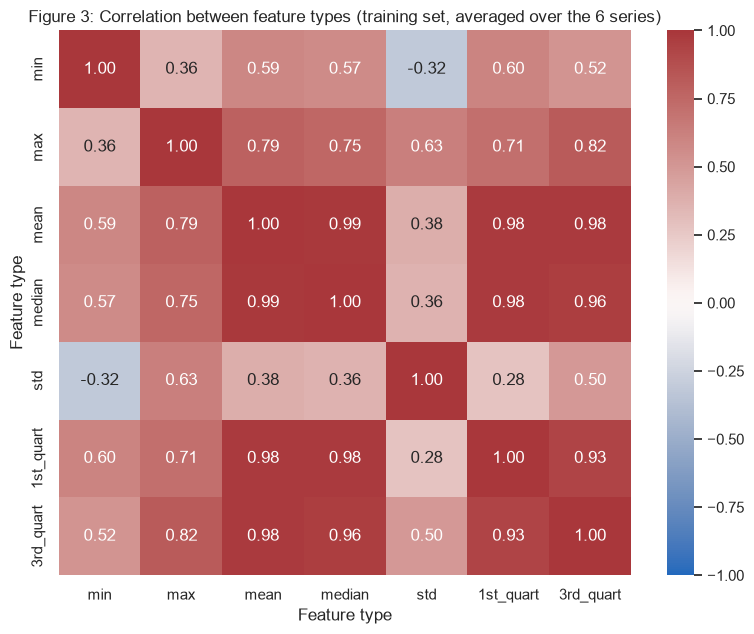

In [9]:
# only the training instances are used to choose the features
train_df = feature_table[feature_table["Split"] == "train"]


def mean_corr(feature_a, feature_b):
    # correlation between two feature types, averaged over the six series
    correlations = []
    for series_num in range(1, 7):
        column_a = train_df[f"{feature_a}{series_num}"]
        column_b = train_df[f"{feature_b}{series_num}"]
        # a constant column has no correlation to report, so it is skipped
        if column_a.nunique() > 1 and column_b.nunique() > 1:
            correlations.append(column_a.corr(column_b))
    return np.mean(correlations) if correlations else np.nan


# which feature types carry the same information
feature_corr = pd.DataFrame(
    [[mean_corr(feature_a, feature_b) for feature_b in FEATURE_NAMES] for feature_a in FEATURE_NAMES],
    index=FEATURE_NAMES, columns=FEATURE_NAMES,
)

# a feature with the same value in every instance cannot help
constant_features = [column for column in features_df.columns if features_df[column].nunique() == 1]
print("Features that are constant in all 88 instances:", constant_features)

fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(feature_corr, annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1, ax=ax)
ax.set(title="Figure 3: Correlation between feature types (training set, averaged over the 6 series)",
       xlabel="Feature type", ylabel="Feature type")
plt.tight_layout()
plt.show()

In [10]:
# how well each feature separates the seven activities
anova_f = pd.DataFrame(
    {
        feature_name: [
            stats.f_oneway(*[group[f"{feature_name}{series_num}"] for _, group in train_df.groupby("Activity")]).statistic
            for series_num in range(1, 7)
        ]
        for feature_name in FEATURE_NAMES
    },
    index=pd.Index([f"{series_num}: {series_name}" for series_num, series_name in enumerate(SERIES_NAMES, start=1)],
                   name="Time series"),
)

# summary rows: the typical F and the average rank of each feature type
anova_f.loc["Median F over series"] = anova_f.median()
anova_f.loc["Mean rank (1 = best)"] = anova_f.iloc[:6].rank(axis=1, ascending=False).mean()
anova_f

,min,max,mean,median,std,1st_quart,3rd_quart
Time series,,,,,,,
1: avg_rss12,10.9696,1.5121,15.8545,17.4893,9.1041,21.3842,8.5445
2: var_rss12,NaN,47.7273,900.1109,477.0135,360.9032,265.4565,807.0489
3: avg_rss13,22.7124,31.6935,26.3647,19.4097,15.2108,21.1924,28.1059
4: var_rss13,NaN,29.3346,652.5120,800.7948,128.6717,244.8186,561.8993
5: avg_rss23,24.0961,36.9528,33.4317,28.6376,7.7749,25.4939,32.2417
6: var_rss23,0.7760,32.9603,581.5501,563.1254,133.4114,346.3418,664.7759
Median F over series,16.8410,32.3269,307.4909,252.8255,71.9413,135.1562,297.0705
Mean rank (1 = best),5.2500,4.5000,2.1667,3.1667,5.5000,4.0000,2.8333


In [11]:
# 4 folds, because the smallest training class has only 4 instances
cv_splitter = RepeatedStratifiedKFold(n_splits=4, n_repeats=10, random_state=SEED)
model_pipeline = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000))

# accuracy of every triple of feature types, 18 features each
triple_rows = []
for feature_triple in combinations(FEATURE_NAMES, 3):
    triple_columns = [f"{feature_name}{series_num}" for feature_name in feature_triple for series_num in range(1, 7)]
    cv_accuracy = cross_val_score(model_pipeline, train_df[triple_columns], train_df["Activity"], cv=cv_splitter).mean()
    triple_rows.append({"Features": ", ".join(feature_triple), "CV accuracy": cv_accuracy})

triple_results = pd.DataFrame(triple_rows).sort_values("CV accuracy", ascending=False).reset_index(drop=True)
triple_results.index += 1
triple_results.index.name = "Rank"
triple_results.head(12)

,Features,CV accuracy
Rank,,
1,"mean, median, std",0.9176
2,"median, std, 3rd_quart",0.9131
3,"mean, std, 3rd_quart",0.9058
4,"max, median, std",0.9012
5,"median, std, 1st_quart",0.9002
6,"max, std, 3rd_quart",0.8984
7,"max, mean, std",0.8955
8,"max, mean, 3rd_quart",0.8927
9,"std, 1st_quart, 3rd_quart",0.8913


In [12]:
# the triple suggested in the question, the one I pick, and the best scoring one
selected_triples = ["min, max, mean", "max, mean, std", "mean, std, 3rd_quart"]
triple_results[triple_results["Features"].isin(selected_triples)]

,Features,CV accuracy
Rank,,
3,"mean, std, 3rd_quart",0.9058
7,"max, mean, std",0.8955
17,"min, max, mean",0.8784


**Answer.** I select **mean, standard deviation and maximum**.

- **Mean (location).** In Figure 3, mean, median, 1st quartile and 3rd quartile are almost interchangeable (average correlation 0.93-0.99). They all measure the typical level of the series, so only one of them is needed. The mean has the best average ANOVA rank (2.17), the largest median $F$ over the six series (307), and very large $F$ values on the variance series (e.g. $F = 900$ for `var_rss12`). The typical signal strength and the typical amount of fluctuation both differ clearly between activities.
- **Standard deviation (spread).** On its own, `std` has a low ANOVA rank (5.5), but it is the **least redundant** feature (correlation only 0.28-0.50 with the location features). It appears in **every one of the top 7 triples** in the cross-validation table. It adds the information the location features miss: how much the signal fluctuates, which separates the dynamic activities (walking, cycling) from the static ones.
- **Maximum (extremes).** Among the remaining features, `max` is the least correlated with the mean (0.79) and captures short spikes in the signal caused by movement. `min` is a poor choice for the third feature. It is constant in all instances for series 2 and 4, nearly constant for series 6, and has the lowest median $F$ (16.8).

The triple **mean, std, max** reaches a cross-validated accuracy of 0.896 (rank 7 of 35). This is within noise of the best triple (mean, median, std: 0.918). The difference of about 2 percentage points corresponds to only about 1.5 of the 69 training instances. The best triple also contains two nearly identical features (mean and median, r = 0.99), so it doesn't add genuinely new information. For comparison, the suggested option **min, mean, max** reaches only 0.878 (rank 17), mainly because the minimum is uninformative for the variance series. So my three most important time-domain features are **mean, standard deviation and maximum**.

## 2. ISLR 3.7.4

*I collect a set of data ($n = 100$ observations) containing a single predictor and a quantitative response. I then fit a linear regression model to the data, as well as a separate cubic regression, i.e. $Y = \beta_0 + \beta_1X + \beta_2X^2 + \beta_3X^3 + \epsilon$.*

### (a) Linear Train

*Suppose that the true relationship between X and Y is linear, i.e. $Y = \beta_0 + \beta_1X + \epsilon$. Consider the training residual sum of squares (RSS) for the linear regression, and also the training RSS for the cubic regression. Would we expect one to be lower than the other, would we expect them to be the same, or is there not enough information to tell? Justify your answer.*

**Answer.** We expect the **cubic regression to have the lower (or at worst equal) training RSS.** The linear model is nested in the cubic model: setting $\beta_2 = \beta_3 = 0$ gives it back. Least squares minimizes the training RSS over all coefficient values, so the cubic fit can always do at least as well as the linear fit on the training data. In practice it does strictly better. The extra terms $X^2$ and $X^3$ fit some of the random noise $\epsilon$ even though the true relationship is linear, so the training RSS drops (only slightly).

### (b) Linear Test

*Answer (a) using test rather than training RSS.*

**Answer.** We expect the **linear regression to have the lower test RSS.** When the truth is linear, both models are unbiased, since the cubic can set $\beta_2=\beta_3=0$. The cubic model estimates two extra coefficients, though, and those estimates chase noise in the training sample. That adds **variance** to its predictions without reducing bias. So on new data the cubic model overfits and its test RSS is expected to be higher. For any particular training/test sample the difference is small and can occasionally go the other way, but on average the linear model wins.

### (c) Not Linear Train

*Suppose that the true relationship between X and Y is not linear, but we don't know how far it is from linear. Consider the training RSS for the linear regression, and also the training RSS for the cubic regression. Would we expect one to be lower than the other, would we expect them to be the same, or is there not enough information to tell? Justify your answer.*

**Answer.** The **cubic regression will have the lower training RSS**, for the same reason as in (a). The linear model is a special case of the cubic model, so the least-squares cubic fit can never have a larger training RSS. This holds for any true relationship. With a nonlinear truth, the gap is usually larger than in (a), because the cubic terms now also capture real curvature.

### (d) Not Linear Testing

*Answer (c) using test rather than training RSS.*

**Answer.** **There is not enough information to tell.** It depends on how far the true relationship is from linear, which we don't know:
- If the truth is **far from linear**, the linear model has large **bias**. The cubic model's extra flexibility removes much of that bias, and its test RSS is lower.
- If the truth is **only slightly nonlinear**, the bias reduction from the cubic terms is smaller than the variance they add, so the linear model can still have the lower test RSS.

It is a bias-variance trade-off, and which side wins depends on the unknown true function (and on the noise level and $n$).

**Simulation check.** To confirm (a)-(d), I simulate 2,000 training sets of $n=100$ observations with $X \sim N(0,1)$ and $\epsilon \sim N(0,1)$. For each one I fit both models and compute the training RSS and the RSS on a fresh test set of 100 observations. I use three true relationships: linear, slightly nonlinear, and strongly nonlinear.

In [13]:
def simulate(true_function, n=100, n_reps=2000, seed=SEED):
    # fit a line and a cubic on the same data, then score both on fresh data
    rng = np.random.default_rng(seed)
    rss = {"train linear": [], "train cubic": [], "test linear": [], "test cubic": []}
    for _ in range(n_reps):
        x_train, x_test = rng.normal(size=n), rng.normal(size=n)
        y_train = true_function(x_train) + rng.normal(size=n)
        y_test = true_function(x_test) + rng.normal(size=n)
        for degree, label in [(1, "linear"), (3, "cubic")]:
            coefficients = np.polyfit(x_train, y_train, degree)
            rss[f"train {label}"].append(np.sum((y_train - np.polyval(coefficients, x_train)) ** 2))
            rss[f"test {label}"].append(np.sum((y_test - np.polyval(coefficients, x_test)) ** 2))

    # average over the repetitions, and how often the cubic wins
    rss = {key: np.array(values) for key, values in rss.items()}
    return {
        "Mean train RSS (linear)": rss["train linear"].mean(),
        "Mean train RSS (cubic)": rss["train cubic"].mean(),
        "Cubic train RSS <= linear": np.mean(rss["train cubic"] <= rss["train linear"] + 1e-9),
        "Mean test RSS (linear)": rss["test linear"].mean(),
        "Mean test RSS (cubic)": rss["test cubic"].mean(),
        "Cubic test RSS < linear": np.mean(rss["test cubic"] < rss["test linear"]),
    }


# a linear truth, a slightly nonlinear one and a strongly nonlinear one
true_functions = {
    "Linear: 2 + 3X": lambda x: 2 + 3 * x,
    "Slightly nonlinear: 2 + 3X + 0.05X^2": lambda x: 2 + 3 * x + 0.05 * x**2,
    "Strongly nonlinear: 2 + 3X + X^2": lambda x: 2 + 3 * x + x**2,
}
pd.DataFrame({name: simulate(true_function) for name, true_function in true_functions.items()}).T

,Mean train RSS (linear),Mean train RSS (cubic),Cubic train RSS <= linear,Mean test RSS (linear),Mean test RSS (cubic),Cubic test RSS < linear
Linear: 2 + 3X,98.3631,96.2665,1.0,102.3752,106.3872,0.2595
Slightly nonlinear: 2 + 3X + 0.05X^2,98.8052,96.2665,1.0,102.8386,106.3872,0.3165
Strongly nonlinear: 2 + 3X + X^2,287.3431,96.2665,1.0,311.8690,106.3872,1.0000


**Answer.** The simulation agrees with (a)-(d):
- **(a) and (c):** the cubic training RSS is **never larger** than the linear one (100% of runs for every true relationship). When the truth is linear, the gain is small (96.3 vs 98.4).
- **(b):** with a linear truth, the **linear model has the lower average test RSS** (102.4 vs 106.4). The cubic model beats it in only 26% of the runs, so the overfitting penalty is real but small.
- **(d):** the answer depends on the truth. With a *slightly* nonlinear truth ($0.05X^2$), the linear model still has the lower average test RSS (102.8 vs 106.4, cubic wins 32% of runs). With a *strongly* nonlinear truth ($X^2$), the cubic model is far better (106.4 vs 311.9, cubic wins 100% of runs).

The cubic model's RSS is identical in all three settings. Each true function is itself a polynomial of degree <= 3, and the same random draws are reused, so the cubic fit always recovers the truth up to the same noise.

## 3. ISLR 3.7.3 - Extra Practice 

*Suppose we have a data set with five predictors, $X_1$ = GPA, $X_2$ = IQ, $X_3$ = Level (1 for College and 0 for High School), $X_4$ = Interaction between GPA and IQ, and $X_5$ = Interaction between GPA and Level. The response is starting salary after graduation (in thousands of dollars). Suppose we use least squares to fit the model, and get $\hat\beta_0 = 50$, $\hat\beta_1 = 20$, $\hat\beta_2 = 0.07$, $\hat\beta_3 = 35$, $\hat\beta_4 = 0.01$, $\hat\beta_5 = -10$.*

**(a) Which answer is correct, and why?**

**Answer. iii.** *"For a fixed value of IQ and GPA, high school graduates earn more, on average, than college graduates provided that the GPA is high enough."* For fixed GPA and IQ, the only terms that differ between the two groups are $\hat\beta_3\,\text{Level}$ and $\hat\beta_5\,\text{GPA}\times\text{Level}$, so

$$\widehat{\text{Salary}}_{\text{college}} - \widehat{\text{Salary}}_{\text{high school}} = 35 - 10\,\text{GPA}.$$

This is positive when GPA < 3.5 (college graduates earn more) and negative when GPA > 3.5 (high school graduates earn more). So high school graduates earn more only when GPA is high enough, which is option iii. Options i and ii are wrong because the sign depends on GPA, and option iv reverses the direction.

**(b) Predict the salary of a college graduate with IQ of 110 and a GPA of 4.0.**

**Answer.** $\widehat{\text{Salary}} = 50 + 20(4.0) + 0.07(110) + 35(1) + 0.01(4.0 \times 110) - 10(4.0 \times 1) = 50 + 80 + 7.7 + 35 + 4.4 - 40 = 137.1$, i.e. **\$137,100**.

**(c) True or false: Since the coefficient for the GPA/IQ interaction term is very small, there is very little evidence of an interaction effect. Justify your answer.**

**Answer. False.** The size of a coefficient says nothing about the *evidence* for the effect. Evidence is judged by the coefficient relative to its standard error, through the $t$-statistic and p-value. Also, the magnitude of $\hat\beta_4$ depends on the units of GPA x IQ, which is typically around 300-450. A coefficient of 0.01 then corresponds to several thousand dollars across the range of the data. If its standard error is small enough, the interaction can be highly significant.

## 3. ISLR 3.7.5 - Extra Practice 

*Consider the fitted values that result from performing linear regression without an intercept. In this setting, the $i$th fitted value takes the form $\hat y_i = x_i\hat\beta$, where $\hat\beta = \left(\sum_{i=1}^n x_i y_i\right) / \left(\sum_{i'=1}^n x_{i'}^2\right)$. Show that we can write $\hat y_i = \sum_{i'=1}^n a_{i'} y_{i'}$. What is $a_{i'}$?*

**Answer.** Rename the summation index in the numerator of $\hat\beta$ to $i'$ and the one in the denominator to $k$, so they don't clash with the fixed $i$:

$$\hat y_i = x_i \hat\beta = x_i\,\frac{\sum_{i'=1}^n x_{i'} y_{i'}}{\sum_{k=1}^n x_k^2} = \sum_{i'=1}^n \underbrace{\frac{x_i\,x_{i'}}{\sum_{k=1}^n x_k^2}}_{a_{i'}}\; y_{i'}.$$

So
$$a_{i'} = \frac{x_i\,x_{i'}}{\sum_{k=1}^n x_k^2}.$$

This shows that each fitted value is a **linear combination of the observed responses**. Least-squares fitted values are weighted averages of the $y$'s, with weights that depend only on the $x$'s (the $a_{i'}$ are the entries of row $i$ of the hat matrix).

### References

1. UCI Machine Learning Repository, *Activity Recognition system based on Multisensor data fusion (AReM) Data Set*: https://archive.ics.uci.edu/dataset/366/activity+recognition+system+based+on+multisensor+data+fusion+arem
2. F. Palumbo, C. Gallicchio, R. Pucci, A. Micheli, "Human activity recognition using multisensor data fusion based on Reservoir Computing," *Journal of Ambient Intelligence and Smart Environments*, 8(2) (2016), 87-107. https://doi.org/10.3233/AIS-160372
3. G. James, D. Witten, T. Hastie, R. Tibshirani, *An Introduction to Statistical Learning* (ISLR), Ch. 3 (linear regression, polynomial regression, interactions; exercises 3.7.3-3.7.5) and Ch. 5.2 (the bootstrap).
4. B. Efron, R. Tibshirani, *An Introduction to the Bootstrap*, Chapman & Hall/CRC, 1993 (percentile confidence intervals).
5. B. Hjorth, "EEG analysis based on time domain properties," *Electroencephalography and Clinical Neurophysiology*, 29(3) (1970), 306-310 (Hjorth parameters).
6. SciPy, `scipy.stats.bootstrap`: https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.bootstrap.html
7. SciPy, `scipy.stats.f_oneway` (one-way ANOVA): https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.f_oneway.html
8. scikit-learn, `LogisticRegression` and `RepeatedStratifiedKFold`: https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html, https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.RepeatedStratifiedKFold.html
9. NumPy, `numpy.percentile` (quartiles) and `numpy.polyfit`: https://numpy.org/doc/stable/reference/generated/numpy.percentile.html